# Regimes, catalysts and event models

Generated data make hidden-state uncertainty, dependent forecasts, and event
clustering inspectable. All computations use Convexity's public interfaces and
local inputs. The [catalog](../docs/regimes_events.md) defines timing conventions
and the bounded model list. Regime numbers are labels, not economic categories.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from convexity.math import distributions as d, regimes as r
rng = np.random.default_rng(120)
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.grid': True})

## Hidden regimes: filtering and smoothing

Filtering sees observations only through the plotted row. Smoothing sees the
entire series, so its earlier probabilities are retrospective. The known model
below isolates inference uncertainty from uncertainty about fitted parameters.
The missing interval contributes no likelihood; regime uncertainty still evolves.

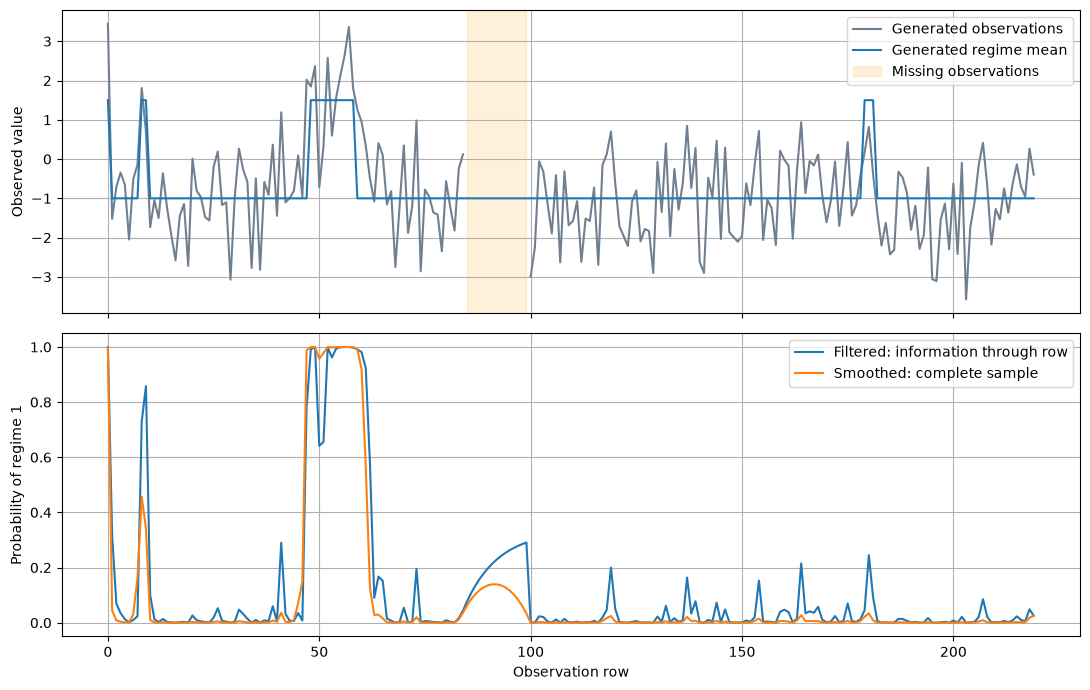

,Stationary probability,Expected duration (rows)
0,0.666667,25.0
1,0.333333,12.5


In [2]:
chain = r.MarkovChain([[.96, .04], [.08, .92]])
model = r.HiddenMarkovModel(chain, [d.normal(-1, 1), d.normal(1.5, 1.2)], [.5, .5])
generated = model.sample(220, rng=rng)
y = generated.values[0].copy()
y[85:100] = np.nan
inferred = model.smooth(y)
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
axes[0].plot(y, color='slategray', label='Generated observations')
axes[0].plot(np.where(generated.regimes[0] == 0, -1, 1.5), label='Generated regime mean')
axes[0].axvspan(85, 99, alpha=.15, color='orange', label='Missing observations')
axes[0].set(ylabel='Observed value')
axes[0].legend()
axes[1].plot(inferred.filtered[:, 1], label='Filtered: information through row')
axes[1].plot(inferred.smoothed[:, 1], label='Smoothed: complete sample')
axes[1].set(xlabel='Observation row', ylabel='Probability of regime 1', ylim=(-.05, 1.05))
axes[1].legend()
plt.tight_layout()
plt.show()
pd.DataFrame({'Stationary probability': chain.stationary(), 'Expected duration (rows)': chain.durations()})

## Fitted switching models and dependent future paths

A separate, well-separated generated sample supports estimation. Labels can
permute, so the table reports fitted labels without assigning them meanings.
Forecast intervals below are pointwise empirical bands, not simultaneous path
bands. Paths share evolving regimes, which generates off-diagonal covariance.
These forecasts condition on fitted parameters and omit parameter uncertainty.

Optimizer converged: True


,Mean,Variance
Regime 0,-2.006287,0.363765
Regime 1,1.971560,0.678524


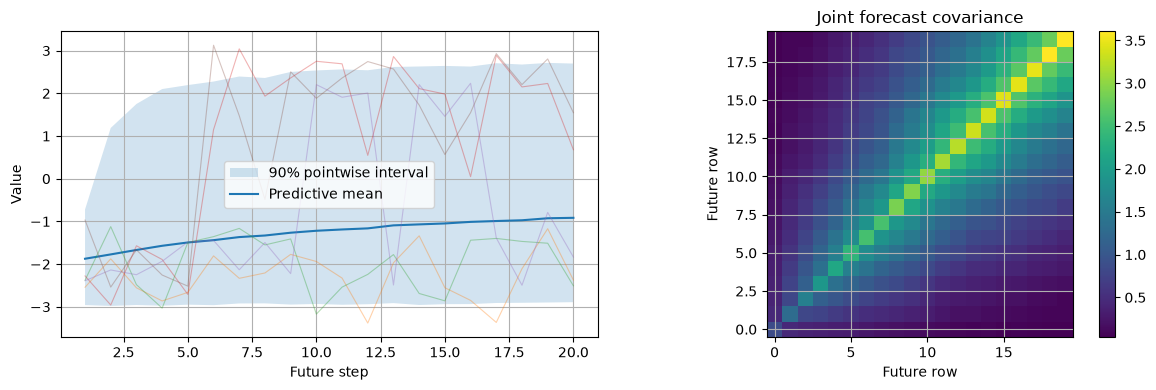

In [3]:
training_model = r.HiddenMarkovModel(chain, [d.normal(-2, .6), d.normal(2, .8)], [.5, .5])
training = training_model.sample(800, rng=rng).values[0]
fitted = r.SwitchingRegression(switching_variance=True).fit(training)
print('Optimizer converged:', fitted.converged)
display(pd.DataFrame({'Mean': fitted.coefficients[:, 0], 'Variance': fitted.variances}, index=['Regime 0', 'Regime 1']))
forecast = fitted.predict(20, draws=5000, rng=rng)
band = forecast.interval(.9)[:, 0]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
steps = np.arange(1, 21)
axes[0].fill_between(steps, band[:, 0], band[:, 1], alpha=.2, label='90% pointwise interval')
axes[0].plot(steps, forecast.mean()[:, 0], label='Predictive mean')
for path in forecast.paths[:5, :, 0]:
    axes[0].plot(steps, path, alpha=.35, linewidth=.8)
axes[0].set(xlabel='Future step', ylabel='Value')
axes[0].legend()
image = axes[1].imshow(forecast.covariance(), origin='lower', cmap='viridis')
axes[1].set(xlabel='Future row', ylabel='Future row', title='Joint forecast covariance')
fig.colorbar(image, ax=axes[1])
plt.tight_layout()
plt.show()

## Scheduled surprises and conditional impacts

An event time can be known while its surprise and effect remain uncertain.
Here impact equals 0.7 times a Student-t surprise plus conditional Gaussian
noise. The paired draws retain this relation; the histogram is an empirical
impact law, not a fitted Gaussian density.

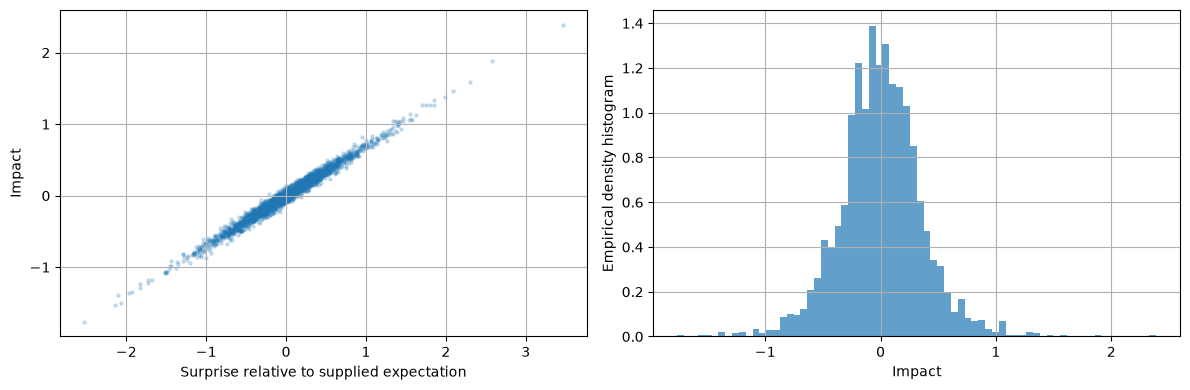

In [4]:
release = r.ScheduledEvent(2, d.student_t(5, scale=.4),
                           lambda surprise: d.normal(.7*surprise, .05), 'release')
surprises, impacts = release.sample(draws=2500, rng=rng)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(surprises, impacts, s=5, alpha=.2)
axes[0].set(xlabel='Surprise relative to supplied expectation', ylabel='Impact')
axes[1].hist(impacts, bins=70, density=True, alpha=.7)
axes[1].set(xlabel='Impact', ylabel='Empirical density histogram')
plt.tight_layout()
plt.show()

## Event arrivals: scheduled rate changes and self-excitation

The Poisson rate below changes at supplied breakpoints. Hawkes intensity
increases after an event, then decays. The Hawkes run starts with empty history;
its stationary mean rate is a reference, not its finite-window initial rate.
Times are numeric in one common caller-selected unit.

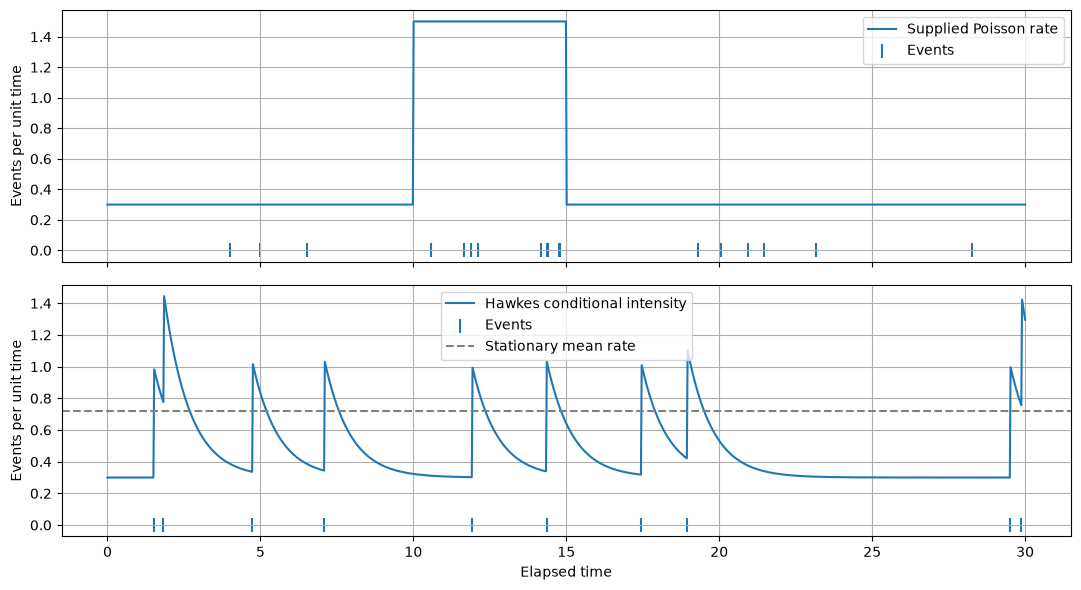

In [5]:
rate = r.PiecewiseConstantIntensity([10, 15], [.3, 1.5, .3])
poisson = r.PoissonProcess(rate)
hawkes = r.ExponentialHawkes(.3, .7, 1.2)
poisson_times = poisson.sample(0, 30, rng=rng)
hawkes_times = hawkes.sample(0, 30, rng=rng)
grid = np.linspace(0, 30, 1200)
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
axes[0].plot(grid, [rate.intensity(t) for t in grid], label='Supplied Poisson rate')
axes[0].scatter(poisson_times, np.zeros(len(poisson_times)), marker='|', s=100, label='Events')
axes[0].set(ylabel='Events per unit time')
axes[0].legend()
axes[1].plot(grid, [hawkes.intensity(t, hawkes_times) for t in grid], label='Hawkes conditional intensity')
axes[1].scatter(hawkes_times, np.zeros(len(hawkes_times)), marker='|', s=100, label='Events')
axes[1].axhline(hawkes.stationary_rate, color='gray', linestyle='--', label='Stationary mean rate')
axes[1].set(xlabel='Elapsed time', ylabel='Events per unit time')
axes[1].legend()
plt.tight_layout()
plt.show()

## Jump totals include uncertainty in event counts

For a compound Poisson total, variance uses the mark's second moment, not only
its variance. The empirical total law includes zero-event realizations at zero.
Correlated vector jump sizes can use the same interface. Monte Carlo estimates
below fluctuate around the analytic values.

In [6]:
marked = r.MarkedPointProcess(r.PoissonProcess(r.ConstantIntensity(.5)), d.normal(-.1, .3))
mean, variance = marked.moments(0, 2)
totals = marked.aggregate(0, 2, draws=5000, rng=rng)
pd.DataFrame({'Analytic': [float(mean), float(variance), np.exp(-1)],
              'Monte Carlo': [float(totals.mean()), float(totals.variance()), float(totals.density(0))]},
             index=['Total mean', 'Total variance', 'Zero-event probability'])

,Analytic,Monte Carlo
Total mean,-0.100000,-0.096388
Total variance,0.100000,0.095313
Zero-event probability,0.367879,0.365600
